<a href="https://colab.research.google.com/github/Sai-kumar13/ITA0515_COMPUTER_VISION/blob/main/CV_Lab_Experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ITA0515 – COMPUTER VISION
**Name:** SAI KUMAR PABBISETTY  
**Reg No:** 192411240  

**Lab record: 40 experiments using Python & OpenCV.**  


## Setup (run first)

In [32]:
import cv2, numpy as np, matplotlib.pyplot as plt, os, base64, subprocess
from skimage import data
from IPython.display import HTML, display
print("OpenCV version:", cv2.__version__)

# Set USE_INPUT = True if you want to type the values (experiments 32-35) instead of using defaults
USE_INPUT = False
def ask(prompt, default, cast=int):
    if USE_INPUT:
        v = input(f"{prompt} [{default}]: ").strip()
        return cast(v) if v else default
    return default

def show(images, titles=None, cols=3, size=4):
    if not isinstance(images, (list, tuple)): images = [images]
    n = len(images); cols = min(cols, n); rows = (n + cols - 1) // cols
    plt.figure(figsize=(size*cols, size*rows))
    for i, im in enumerate(images):
        plt.subplot(rows, cols, i+1)
        if im.ndim == 2: plt.imshow(im, cmap='gray')
        else: plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        if titles: plt.title(titles[i])
        plt.axis('off')
    plt.tight_layout(); plt.show(); plt.close('all')

def load_image(name='astronaut'):
    """Built-in sample image (BGR, as OpenCV expects)."""
    return cv2.cvtColor(getattr(data, name)(), cv2.COLOR_RGB2BGR)

def read_frames(path):
    cap = cv2.VideoCapture(path); fps = cap.get(cv2.CAP_PROP_FPS) or 30; frames = []
    while True:
        ok, f = cap.read()
        if not ok: break
        frames.append(f)
    cap.release(); return frames, fps

def write_video(path, frames, fps=30):
    h, w = frames[0].shape[:2]
    out = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*'MJPG'), fps, (w, h))
    for f in frames: out.write(f)
    out.release()

def play(path, width=360):
    """Show a video in the notebook (converted to browser-friendly mp4 with ffmpeg)."""
    try:
        out = path.rsplit('.', 1)[0] + '_web.mp4'
        subprocess.run(['ffmpeg','-y','-loglevel','error','-i',path,'-vcodec','libx264','-pix_fmt','yuv420p',out], check=True)
        b64 = base64.b64encode(open(out,'rb').read()).decode()
        display(HTML(f'<video width="{width}" controls loop><source src="data:video/mp4;base64,{b64}" type="video/mp4"></video>'))
    except Exception as e:
        print("Could not embed video player:", e)

def make_moving_video(path='captured.avi', n=90, w=320, h=240, fps=30):
    """Generates a sample 'captured' video: a ball and a square moving over a coloured background."""
    frames = []
    for i in range(n):
        f = np.full((h, w, 3), (200, 225, 235), np.uint8)
        cv2.circle(f, (30 + int(i*(w-60)/n), 70 + int(35*np.sin(i/8))), 22, (0, 0, 255), -1)
        cv2.rectangle(f, (w-60-int(i*(w-100)/n), 150), (w-20-int(i*(w-100)/n), 190), (255, 80, 0), -1)
        cv2.putText(f, f"Frame {i}", (10, 230), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,0,0), 2)
        frames.append(f)
    write_video(path, frames, fps); return path

def haar(name):
    """Load a Haar cascade (uses OpenCV's bundled copy; downloads it from GitHub if missing)."""
    p = os.path.join(cv2.data.haarcascades, name) if hasattr(cv2, 'data') else name
    if not os.path.exists(p):
        p = name
        if not os.path.exists(p):
            import urllib.request
            urllib.request.urlretrieve("https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/" + name, p)
    c = cv2.CascadeClassifier(p)
    assert not c.empty(), "Could not load cascade " + name
    return c
print("Setup complete ✔")

OpenCV version: 5.0.0
Setup complete ✔


## Experiment 1 – Read an image and convert it to Gray-scale

Original shape: (512, 512, 3) | Gray shape: (512, 512)


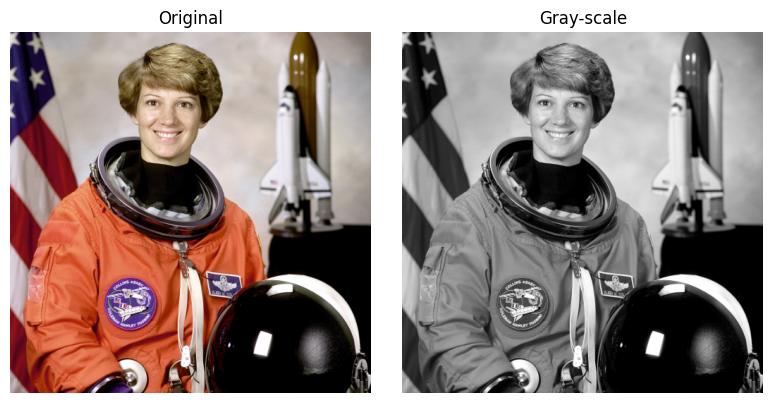

In [33]:
img = load_image('astronaut')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print("Original shape:", img.shape, "| Gray shape:", gray.shape)
show([img, gray], ["Original", "Gray-scale"], cols=2)

## Experiment 2 – Gaussian Blur

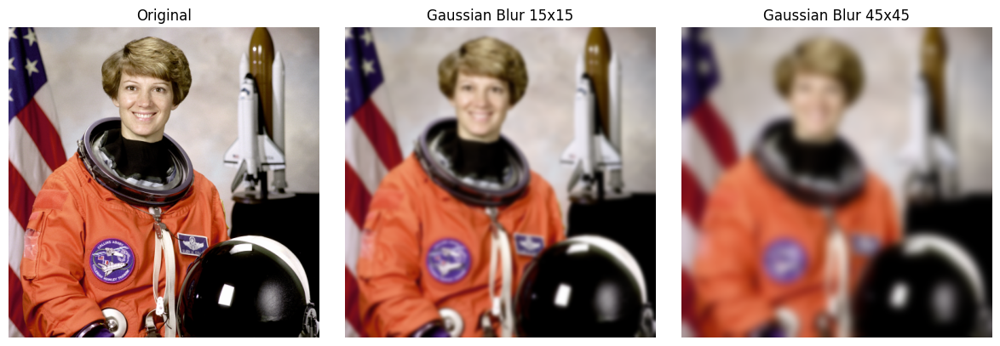

In [34]:
img = load_image('astronaut')
blur = cv2.GaussianBlur(img, (15, 15), 0)
blur_strong = cv2.GaussianBlur(img, (45, 45), 0)
show([img, blur, blur_strong], ["Original", "Gaussian Blur 15x15", "Gaussian Blur 45x45"])

## Experiment 3 – Outline using Canny

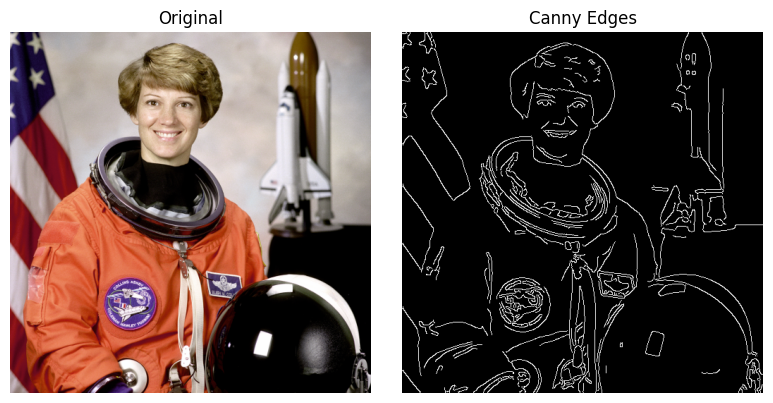

In [35]:
img = load_image('astronaut')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(cv2.GaussianBlur(gray, (5,5), 0), 100, 200)
show([img, edges], ["Original", "Canny Edges"], cols=2)

## Experiment 4 – Histogram Equalization (compare with original)

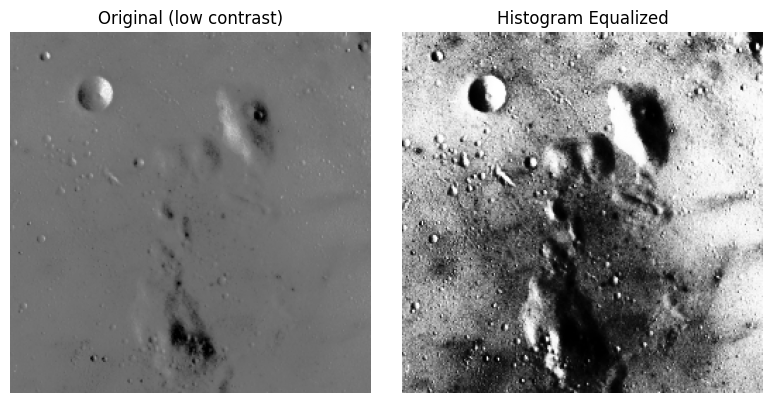

/tmp/ipykernel_568/2734429085.py:5: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.subplot(1,2,1); plt.hist(gray.ravel(), 256, [0,256]); plt.title("Original histogram")
/tmp/ipykernel_568/2734429085.py:6: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.subplot(1,2,2); plt.hist(eq.ravel(), 256, [0,256]); plt.title("Equalized histogram")


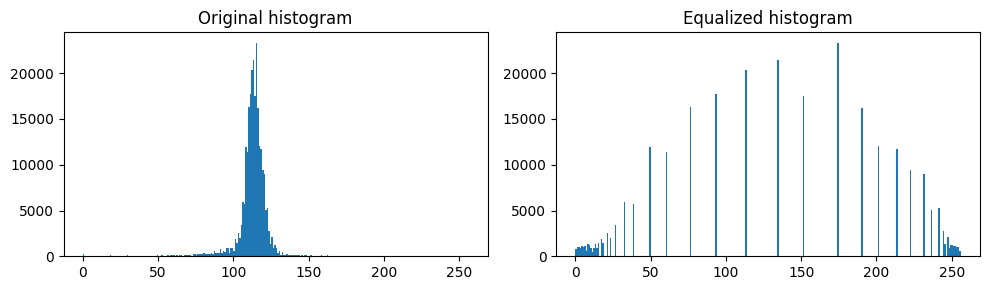

In [36]:
gray = cv2.cvtColor(load_image('moon') if False else cv2.cvtColor(data.moon(), cv2.COLOR_GRAY2BGR), cv2.COLOR_BGR2GRAY)  # low-contrast image
eq = cv2.equalizeHist(gray)
show([gray, eq], ["Original (low contrast)", "Histogram Equalized"], cols=2)
plt.figure(figsize=(10,3))
plt.subplot(1,2,1); plt.hist(gray.ravel(), 256, [0,256]); plt.title("Original histogram")
plt.subplot(1,2,2); plt.hist(eq.ravel(), 256, [0,256]); plt.title("Equalized histogram")
plt.tight_layout(); plt.show()

## Experiment 5 – Histogram analysis based on colour levels

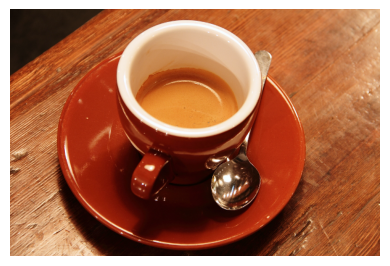

Blue : mean= 51.48  dominant level=  2  dark(0-85)= 81.5%  mid(86-170)= 13.9%  bright(171-255)=  4.6%
Green: mean= 85.79  dominant level=  4  dark(0-85)= 51.9%  mid(86-170)= 38.2%  bright(171-255)=  9.9%
Red  : mean=158.57  dominant level=196  dark(0-85)= 17.6%  mid(86-170)= 27.6%  bright(171-255)= 54.9%


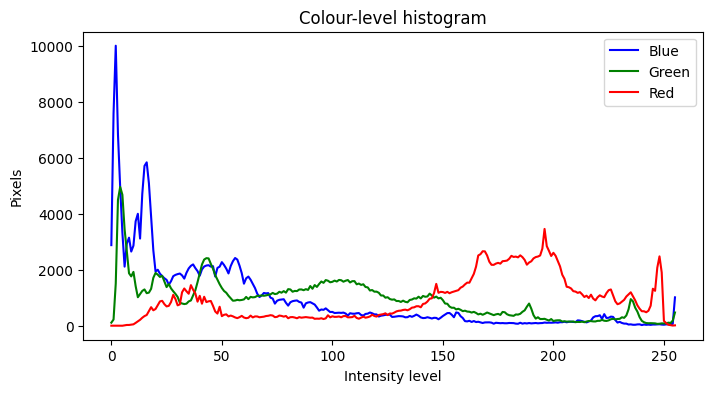

In [37]:
def analyze_histogram(img):
    colors = ('b', 'g', 'r'); names = ('Blue', 'Green', 'Red')
    plt.figure(figsize=(8, 4))
    for i, c in enumerate(colors):
        h = cv2.calcHist([img], [i], None, [256], [0, 256])
        plt.plot(h, color=c, label=names[i])
        ch = img[:, :, i]
        total = ch.size
        print(f"{names[i]:5s}: mean={ch.mean():6.2f}  dominant level={int(np.argmax(h)):3d}  "
              f"dark(0-85)={np.sum(ch<86)/total*100:5.1f}%  mid(86-170)={np.sum((ch>=86)&(ch<171))/total*100:5.1f}%  "
              f"bright(171-255)={np.sum(ch>170)/total*100:5.1f}%")
    plt.title("Colour-level histogram"); plt.xlabel("Intensity level"); plt.ylabel("Pixels"); plt.legend(); plt.show()

img = load_image('coffee')
show(img); analyze_histogram(img)

## Experiment 6 – Erode

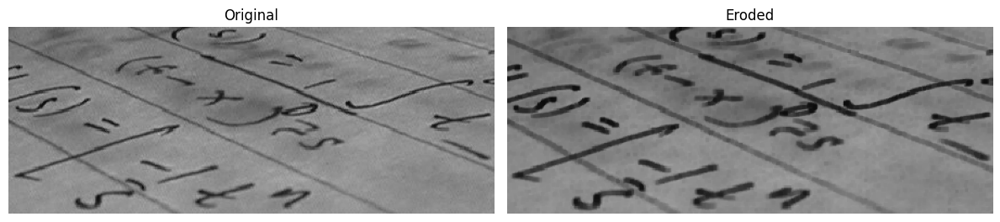

In [38]:
img = cv2.cvtColor(data.text(), cv2.COLOR_GRAY2BGR)
kernel = np.ones((3,3), np.uint8)
eroded = cv2.erode(img, kernel, iterations=1)
show([img, eroded], ["Original", "Eroded"], cols=2, size=6)

## Experiment 7 – Video processing: display, slow motion and fast motion

Read 90 frames at 30.0 fps


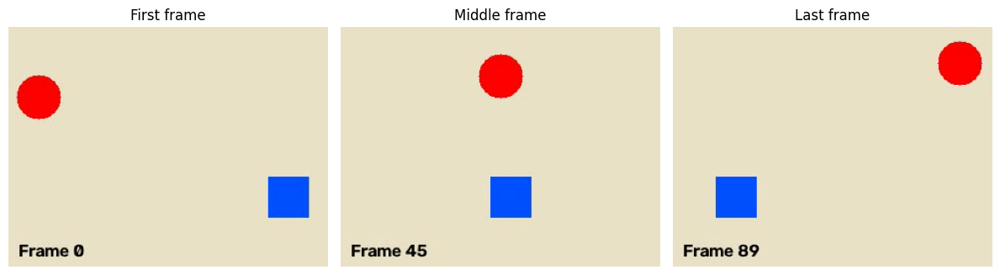

Normal speed:


Slow motion (0.25x):


Fast motion (4x):


In [39]:
make_moving_video('captured.avi')
frames, fps = read_frames('captured.avi')
print(f"Read {len(frames)} frames at {fps} fps")
slow = [f for f in frames for _ in range(4)]   # each frame shown 4 times -> 4x slower
fast = frames[::4]                              # every 4th frame      -> 4x faster
write_video('slow.avi', slow, fps); write_video('fast.avi', fast, fps)
show([frames[0], frames[len(frames)//2], frames[-1]], ["First frame", "Middle frame", "Last frame"])
print("Normal speed:"); play('captured.avi')
print("Slow motion (0.25x):"); play('slow.avi')
print("Fast motion (4x):"); play('fast.avi')

## Experiment 8 – Dilate

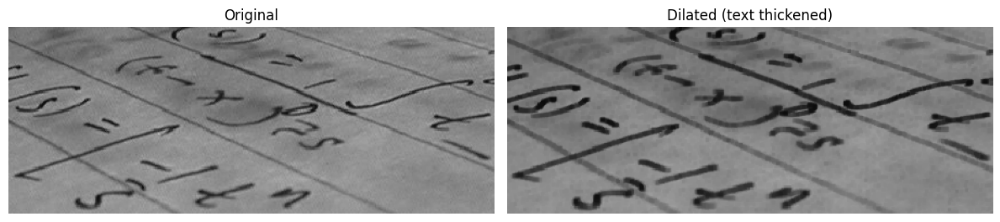

In [40]:
img = cv2.cvtColor(data.text(), cv2.COLOR_GRAY2BGR)
dilated = cv2.dilate(255 - img, np.ones((3,3), np.uint8), iterations=1)
show([img, 255 - dilated], ["Original", "Dilated (text thickened)"], cols=2, size=6)

## Experiment 9 – Image scaling (bigger and smaller)

Original        : 512 x 512
Bigger (1.5x)   : 768 x 768
Smaller (0.4x)  : 205 x 205
Custom 300x150  : 300 x 150


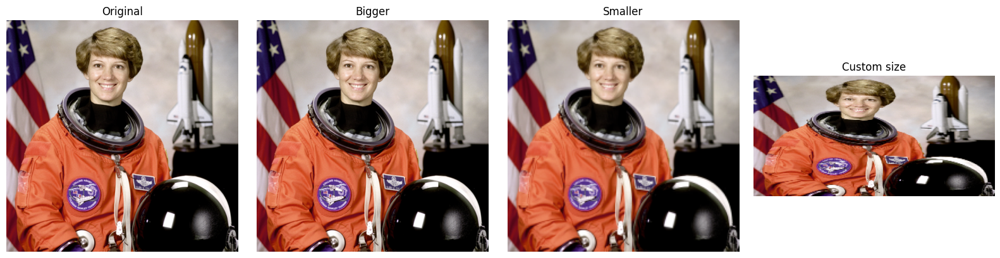

In [41]:
img = load_image('astronaut')
bigger  = cv2.resize(img, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_CUBIC)
smaller = cv2.resize(img, None, fx=0.4, fy=0.4, interpolation=cv2.INTER_AREA)
custom  = cv2.resize(img, (300, 150), interpolation=cv2.INTER_LINEAR)
for t, im in [("Original", img), ("Bigger (1.5x)", bigger), ("Smaller (0.4x)", smaller), ("Custom 300x150", custom)]:
    print(f"{t:16s}: {im.shape[1]} x {im.shape[0]}")
show([img, bigger, smaller, custom], ["Original", "Bigger", "Smaller", "Custom size"], cols=4)

## Experiments 10, 11, 12 – Rotation by 90°, 180°, 270° (clockwise)
`cv2.rotate` rotates the image in the image plane. For 180° the notebook also shows the horizontal flip (mirror about the vertical/y-axis).

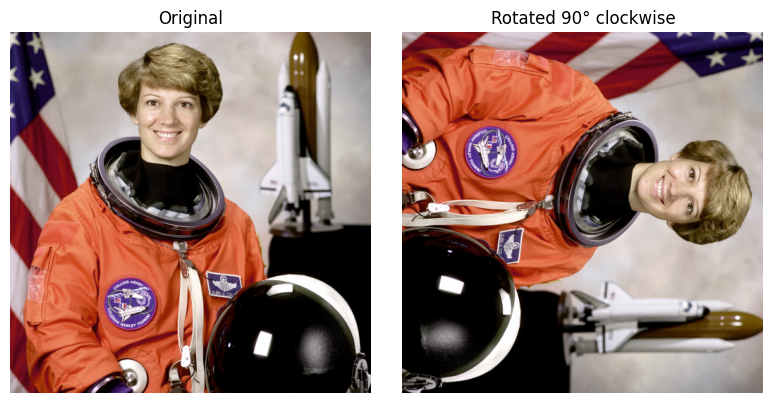

In [42]:
# Experiment 10 : 90 degrees clockwise
img = load_image('astronaut')
r90 = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
show([img, r90], ["Original", "Rotated 90° clockwise"], cols=2)

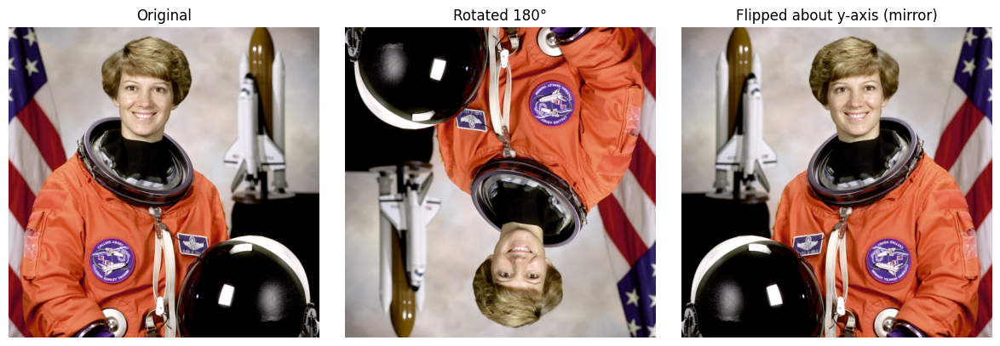

In [43]:
# Experiment 11 : 180 degrees clockwise
img = load_image('astronaut')
r180 = cv2.rotate(img, cv2.ROTATE_180)
mirror_y = cv2.flip(img, 1)   # flip about the vertical (y) axis
show([img, r180, mirror_y], ["Original", "Rotated 180°", "Flipped about y-axis (mirror)"])

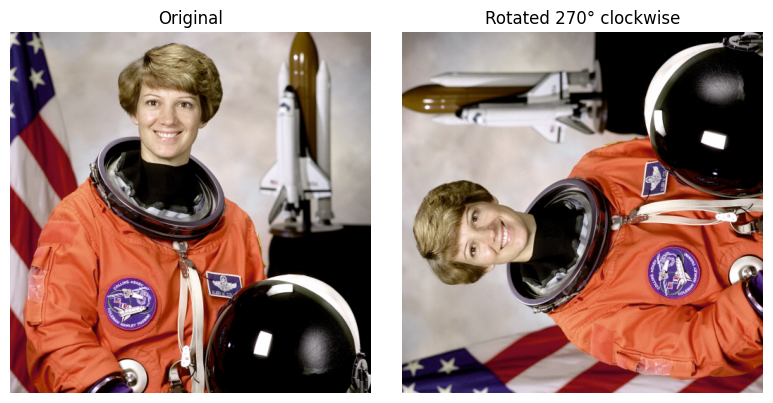

In [44]:
# Experiment 12 : 270 degrees clockwise
img = load_image('astronaut')
r270 = cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE)  # = 270 deg clockwise
show([img, r270], ["Original", "Rotated 270° clockwise"], cols=2)

## Experiment 13 – Affine Transformation

Affine matrix:
 [[ 0.75146773  0.1001957  51.20000076]
 [-0.1001957   0.70136988 76.80000305]]


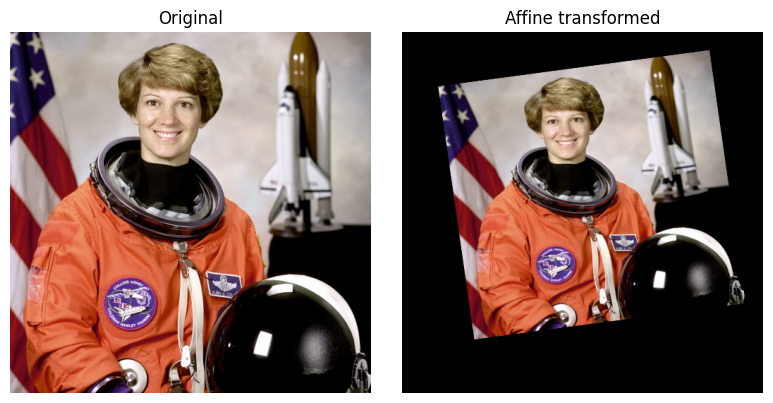

In [45]:
img = load_image('astronaut'); h, w = img.shape[:2]
src = np.float32([[0, 0], [w-1, 0], [0, h-1]])
dst = np.float32([[0.1*w, 0.15*h], [0.85*w, 0.05*h], [0.2*w, 0.85*h]])
M = cv2.getAffineTransform(src, dst)
print("Affine matrix:\n", M)
affine = cv2.warpAffine(img, M, (w, h))
show([img, affine], ["Original", "Affine transformed"], cols=2)

## Experiment 14 – Perspective Transformation

Perspective matrix:
 [[ 6.43703016e-01 -1.13365964e-01  8.00000000e+01]
 [-7.82778865e-02  6.15638383e-01  4.00000000e+01]
 [-1.45714606e-05 -5.17286852e-04  1.00000000e+00]]


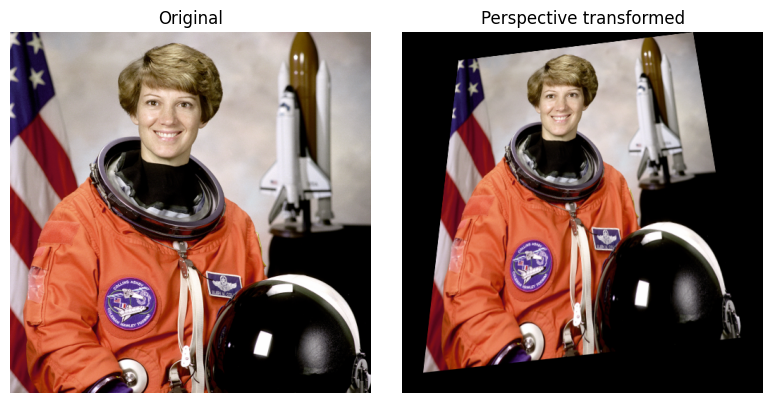

In [46]:
img = load_image('astronaut'); h, w = img.shape[:2]
src = np.float32([[0, 0], [w-1, 0], [0, h-1], [w-1, h-1]])
dst = np.float32([[80, 40], [w-100, 0], [30, h-30], [w-30, h-80]])
M = cv2.getPerspectiveTransform(src, dst)
print("Perspective matrix:\n", M)
persp = cv2.warpPerspective(img, M, (w, h))
show([img, persp], ["Original", "Perspective transformed"], cols=2)

## Experiment 15 – Harris Corner Detection

Corner pixels detected: 1225


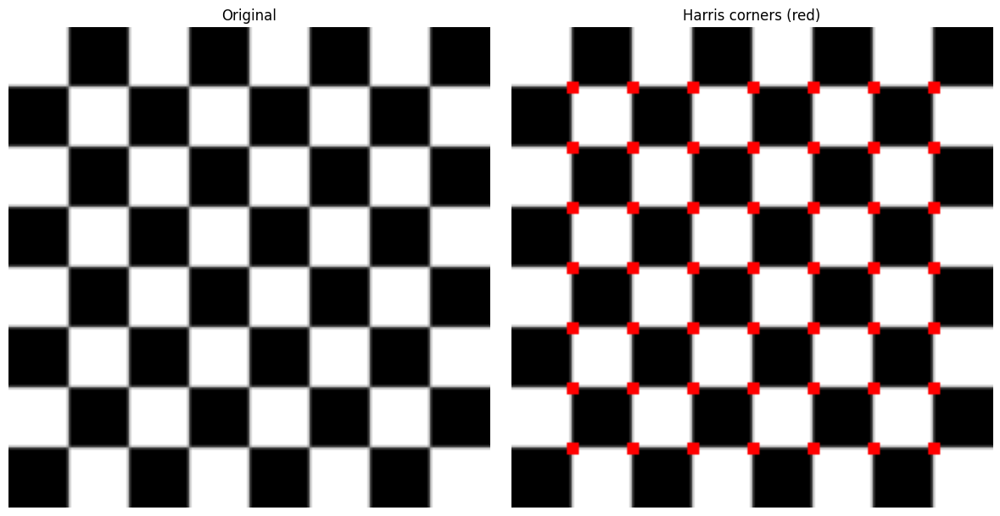

In [47]:
img = cv2.cvtColor(data.checkerboard(), cv2.COLOR_GRAY2BGR)
gray = np.float32(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY))
harris = cv2.cornerHarris(gray, blockSize=2, ksize=3, k=0.04)
harris = cv2.dilate(harris, None)
out = img.copy(); out[harris > 0.01 * harris.max()] = (0, 0, 255)
print("Corner pixels detected:", int((harris > 0.01 * harris.max()).sum()))
show([img, out], ["Original", "Harris corners (red)"], cols=2, size=6)

## Experiment 16 – Sobel filter

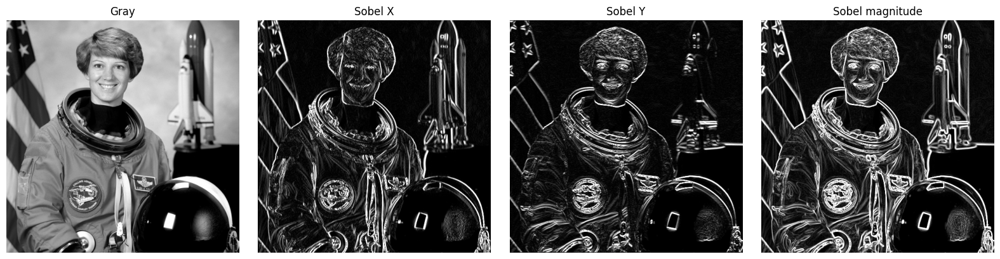

In [48]:
gray = cv2.cvtColor(load_image('astronaut'), cv2.COLOR_BGR2GRAY)
sx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
mag = cv2.convertScaleAbs(cv2.magnitude(sx, sy))
show([gray, cv2.convertScaleAbs(sx), cv2.convertScaleAbs(sy), mag], ["Gray", "Sobel X", "Sobel Y", "Sobel magnitude"], cols=4)

## Experiment 17 – Watermarking

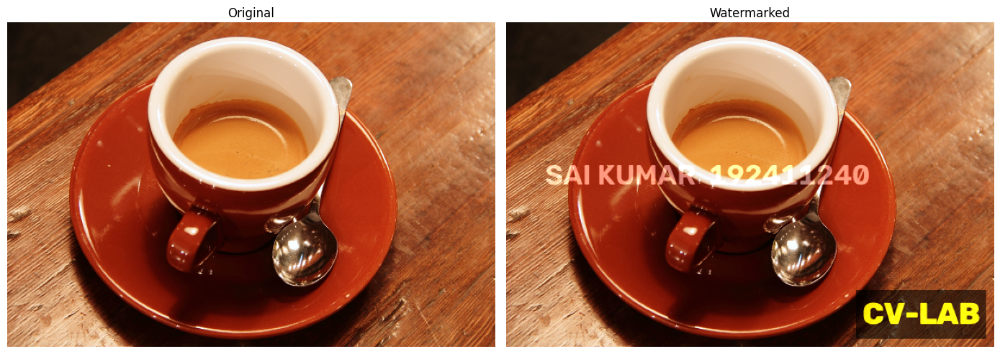

True

In [49]:
img = load_image('coffee'); h, w = img.shape[:2]
# (a) text watermark blended across the image
wm = np.zeros_like(img)
cv2.putText(wm, "SAI KUMAR  192411240", (int(w*0.08), int(h*0.5)), cv2.FONT_HERSHEY_SIMPLEX, w/500, (255,255,255), 3)
marked = cv2.addWeighted(img, 1.0, wm, 0.45, 0)
# (b) logo watermark blended into the bottom-right corner
logo = np.zeros((60, 160, 3), np.uint8); cv2.putText(logo, "CV-LAB", (8, 42), cv2.FONT_HERSHEY_DUPLEX, 1.3, (0,255,255), 2)
roi = img[h-70:h-10, w-170:w-10]
marked2 = marked.copy(); marked2[h-70:h-10, w-170:w-10] = cv2.addWeighted(roi, 0.4, logo, 0.9, 0)
show([img, marked2], ["Original", "Watermarked"], cols=2, size=7)
cv2.imwrite("watermarked.png", marked2)

## Experiment 18 – Crop, copy and paste a Region of Interest (ROI)

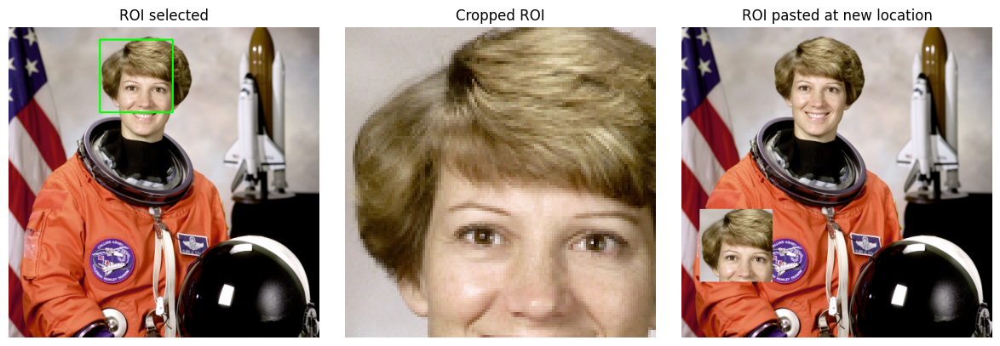

In [50]:
img = load_image('astronaut'); h, w = img.shape[:2]
x1, y1, x2, y2 = 150, 20, 270, 140                 # ROI = face region
roi = img[y1:y2, x1:x2].copy()                    # crop
out = img.copy(); cv2.rectangle(out, (x1, y1), (x2, y2), (0, 255, 0), 2)
pasted = img.copy(); pasted[300:300+(y2-y1), 30:30+(x2-x1)] = roi   # copy + paste elsewhere
show([out, roi, pasted], ["ROI selected", "Cropped ROI", "ROI pasted at new location"])

## Experiments 19–24 – Morphological operations

In [51]:
# Common images for 19-24
text_gray = data.text()
_, binary = cv2.threshold(text_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)   # white foreground on black
coins = data.coins()
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
print("Ready")

Ready


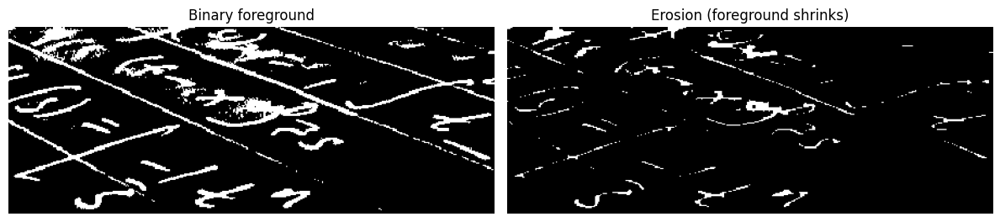

In [52]:
# Experiment 19 : Erosion
er = cv2.morphologyEx(binary, cv2.MORPH_ERODE, kernel, iterations=1)
show([binary, er], ["Binary foreground", "Erosion (foreground shrinks)"], cols=2, size=6)

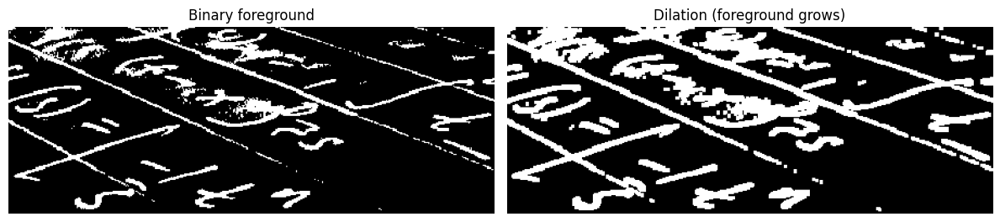

In [53]:
# Experiment 20 : Dilation
di = cv2.morphologyEx(binary, cv2.MORPH_DILATE, kernel, iterations=1)
show([binary, di], ["Binary foreground", "Dilation (foreground grows)"], cols=2, size=6)

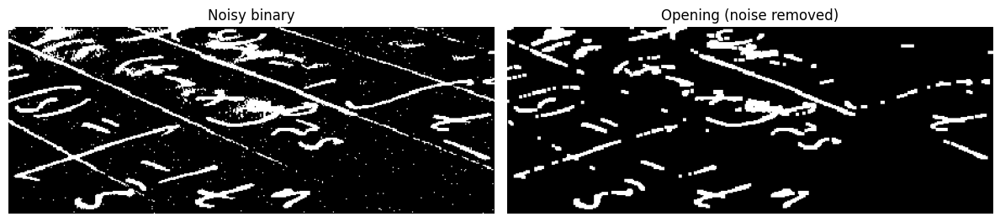

In [54]:
# Experiment 21 : Opening  (erosion followed by dilation)
noisy = binary.copy(); rng = np.random.default_rng(0)
noisy[rng.random(noisy.shape) > 0.995] = 255          # add white salt noise
op = cv2.morphologyEx(noisy, cv2.MORPH_OPEN, kernel)
show([noisy, op], ["Noisy binary", "Opening (noise removed)"], cols=2, size=6)

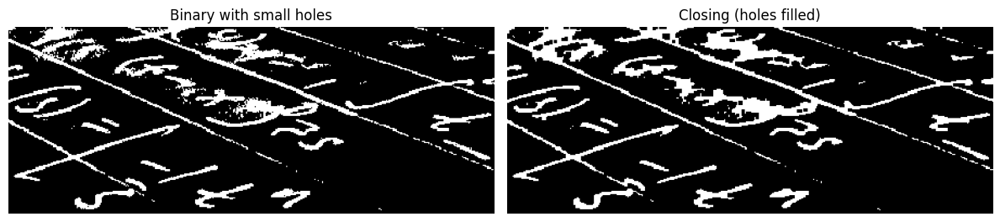

In [55]:
# Experiment 22 : Closing  (dilation followed by erosion)
holes = binary.copy(); holes[rng.random(holes.shape) > 0.995] = 0   # add black pepper holes
cl = cv2.morphologyEx(holes, cv2.MORPH_CLOSE, kernel)
show([holes, cl], ["Binary with small holes", "Closing (holes filled)"], cols=2, size=6)

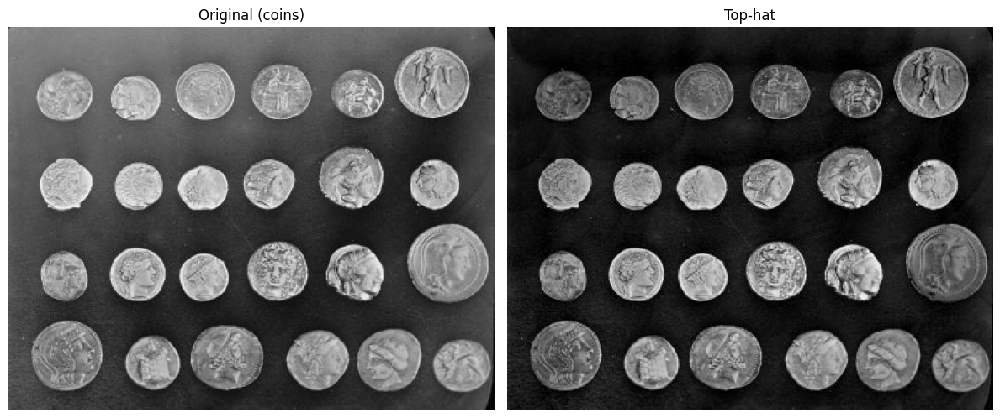

In [56]:
# Experiment 23 : Top-hat  (original - opening) -> bright details smaller than the kernel
k_big = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (61, 61))
th = cv2.morphologyEx(coins, cv2.MORPH_TOPHAT, k_big)
show([coins, th], ["Original (coins)", "Top-hat"], cols=2, size=6)

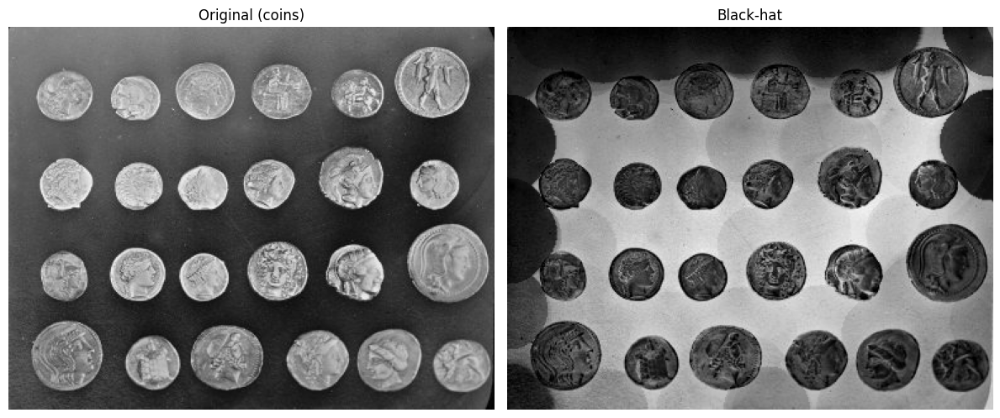

In [57]:
# Experiment 24 : Black-hat  (closing - original) -> dark details smaller than the kernel
bh = cv2.morphologyEx(coins, cv2.MORPH_BLACKHAT, k_big)
show([coins, bh], ["Original (coins)", "Black-hat"], cols=2, size=6)

## Experiment 25 – Recognise a watch (general object recognition)

Watches recognised: 1


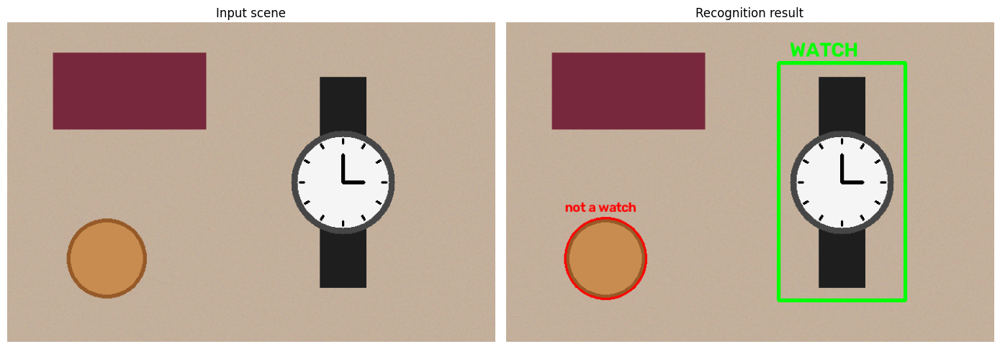

In [58]:
def draw_watch(canvas, c, r):
    x, y = c
    cv2.rectangle(canvas, (x - r//2, y - int(r*2.3)), (x + r//2, y + int(r*2.3)), (30, 30, 30), -1)   # strap
    cv2.circle(canvas, c, r + 8, (70, 70, 70), -1)                                                   # case
    cv2.circle(canvas, c, r, (245, 245, 245), -1)                                                    # dial
    for k in range(12):
        a = np.deg2rad(k*30); p1 = (int(x + 0.85*r*np.sin(a)), int(y - 0.85*r*np.cos(a))); p2 = (int(x + 0.95*r*np.sin(a)), int(y - 0.95*r*np.cos(a)))
        cv2.line(canvas, p1, p2, (0, 0, 0), 2)
    cv2.line(canvas, c, (x, y - int(0.6*r)), (0, 0, 0), 4); cv2.line(canvas, c, (x + int(0.45*r), y), (0, 0, 0), 3)

# Build a scene: one watch + a distractor coin (circle without strap) + a book
rng = np.random.default_rng(1)
scene = np.full((420, 640, 3), (150, 170, 190), np.uint8)
scene = cv2.add(scene, rng.integers(0, 12, scene.shape, dtype=np.uint8))
draw_watch(scene, (440, 210), 60)
cv2.circle(scene, (130, 310), 50, (80, 140, 200), -1); cv2.circle(scene, (130, 310), 50, (40, 90, 150), 4)  # coin
cv2.rectangle(scene, (60, 40), (260, 140), (60, 40, 120), -1)

gray = cv2.medianBlur(cv2.cvtColor(scene, cv2.COLOR_BGR2GRAY), 5)
circles = cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, dp=1.2, minDist=80, param1=100, param2=35, minRadius=40, maxRadius=80)
result = scene.copy(); found = 0
if circles is not None:
    for x, y, r in np.round(circles[0]).astype(int):
        # A watch = round dial + dark strap above AND below it
        up = gray[max(0, y - int(r*2.2)): max(1, y - r - 8), max(0, x - 5): x + 5]
        dn = gray[y + r + 8: y + int(r*2.2), max(0, x - 5): x + 5]
        if up.size and dn.size and up.mean() < 70 and dn.mean() < 70:
            cv2.rectangle(result, (x - r - 15, y - int(r*2.3)), (x + r + 15, y + int(r*2.3)), (0, 255, 0), 3)
            cv2.putText(result, "WATCH", (x - r, y - int(r*2.3) - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2); found += 1
        else:
            cv2.circle(result, (x, y), r, (0, 0, 255), 2); cv2.putText(result, "not a watch", (x - r, y - r - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
print("Watches recognised:", found)
show([scene, result], ["Input scene", "Recognition result"], cols=2, size=7)

## Experiment 26 – Reverse the frames of a video

In [59]:
make_moving_video('captured.avi')
frames, fps = read_frames('captured.avi')
def reverse_video(src, dst):
    fr, f = read_frames(src); write_video(dst, fr[::-1], f); return len(fr)
n = reverse_video('captured.avi', 'reversed.avi')
print(f"Reversed {n} frames")
print("Original:"); play('captured.avi')
print("Reversed:"); play('reversed.avi')

Reversed 90 frames
Original:


Reversed:


## Experiment 27 – Face detection

Faces found: 1


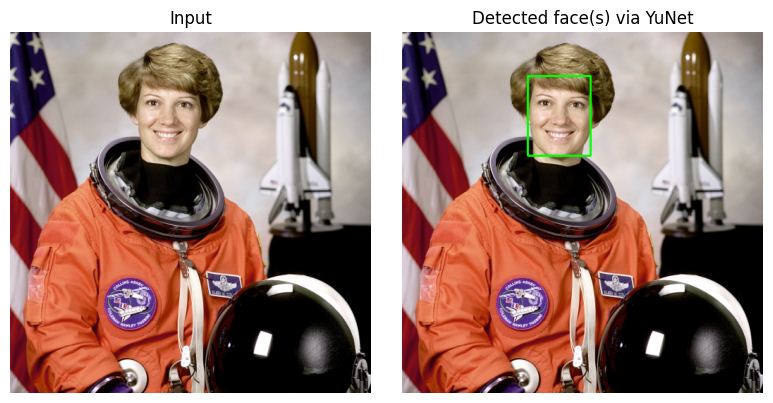

In [61]:
import os

img = load_image('astronaut')
h, w, _ = img.shape

# Ensure the modern YuNet ONNX model is available locally
model_path = "face_detection_yunet_2023mar.onnx"
if not os.path.exists(model_path):
    import urllib.request
    model_url = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
    urllib.request.urlretrieve(model_url, model_path)

# Use modern OpenCV 5 FaceDetectorYN
detector = cv2.FaceDetectorYN.create(
    model=model_path,
    config="",
    input_size=(w, h),
    score_threshold=0.9,
    nms_threshold=0.3,
    top_k=5000
)

_, faces = detector.detect(img)
out = img.copy()

if faces is not None:
    for face in faces:
        box = list(map(int, face[:4]))
        x, y, face_w, face_h = box
        cv2.rectangle(out, (x, y), (x + face_w, y + face_h), (0, 255, 0), 2)
    print("Faces found:", len(faces))
else:
    print("Faces found: 0")

show([img, out], ["Input", "Detected face(s) via YuNet"], cols=2)

### Alternative Face Detection using OpenCV 5 YuNet (DNN)

Faces found: 1


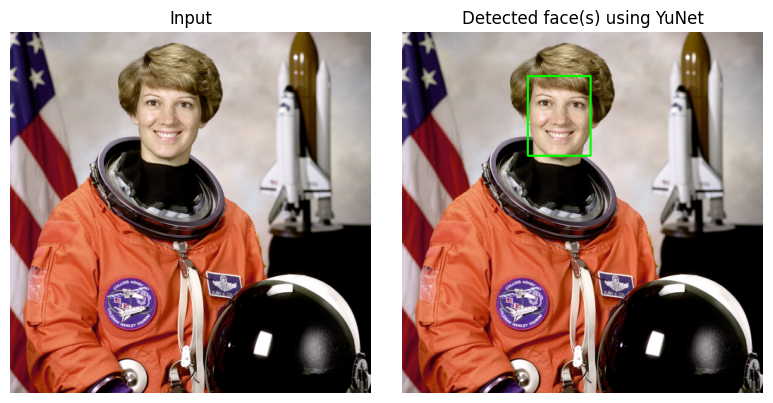

In [62]:
import urllib.request

# Download the YuNet face detection model (ONNX format)
model_url = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
model_path = "face_detection_yunet_2023mar.onnx"
urllib.request.urlretrieve(model_url, model_path)

# Load the astronaut image
img = load_image('astronaut')
h, w, _ = img.shape

# Initialize the face detector with the model and input size
detector = cv2.FaceDetectorYN.create(
    model=model_path,
    config="",
    input_size=(w, h),
    score_threshold=0.9,
    nms_threshold=0.3,
    top_k=5000
)

# Run the face detector
_, faces = detector.detect(img)

out = img.copy()
if faces is not None:
    for face in faces:
        # Box coordinates are the first 4 elements
        box = list(map(int, face[:4]))
        x, y, face_w, face_h = box
        cv2.rectangle(out, (x, y), (x + face_w, y + face_h), (0, 255, 0), 2)
    print(f"Faces found: {len(faces)}")
else:
    print("No faces found.")

show([img, out], ["Input", "Detected face(s) using YuNet"], cols=2)

## Experiment 28 – Vehicle detection in each frame of a video

Max vehicles in a frame: 4


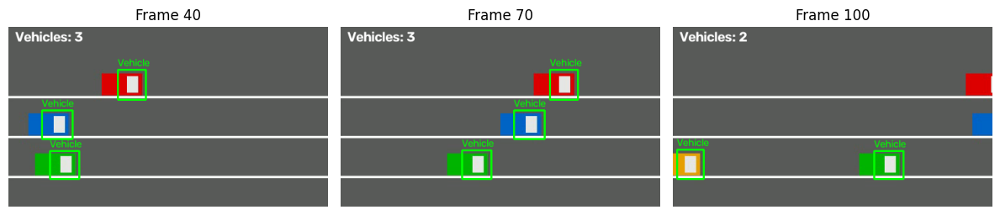

In [63]:
# Generate a traffic video (cars = coloured rectangles moving along 3 lanes)
def make_traffic_video(path='traffic.avi', n=120, w=480, h=270, fps=25):
    frames = []
    cars = [dict(y=70,  v=5, x0=-60, c=(0,0,220)), dict(y=130, v=7, x0=-250, c=(200,100,0)), dict(y=190, v=4, x0=-120, c=(0,180,0)), dict(y=190, v=4, x0=-420, c=(0,160,230))]
    for i in range(n):
        f = np.full((h, w, 3), (90, 90, 90), np.uint8)
        for ly in (105, 165, 225): cv2.line(f, (0, ly), (w, ly), (255,255,255), 2, cv2.LINE_AA)
        for c in cars:
            x = c['x0'] + c['v']*i
            cv2.rectangle(f, (x, c['y']), (x+60, c['y']+32), c['c'], -1); cv2.rectangle(f, (x+38, c['y']+4), (x+54, c['y']+28), (230,230,230), -1)
        frames.append(f)
    write_video(path, frames, fps); return path

make_traffic_video('traffic.avi')
frames, fps = read_frames('traffic.avi')
bg = cv2.createBackgroundSubtractorMOG2(history=50, varThreshold=40, detectShadows=False)
k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)); out_frames = []; counts = []
for f in frames:
    mask = bg.apply(f); mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k); mask = cv2.dilate(mask, k, iterations=2)
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    vis = f.copy(); n = 0
    for c in cnts:
        if cv2.contourArea(c) > 600:
            x, y, w, h = cv2.boundingRect(c); cv2.rectangle(vis, (x, y), (x+w, y+h), (0, 255, 0), 2); cv2.putText(vis, "Vehicle", (x, y-5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,0), 1); n += 1
    cv2.putText(vis, f"Vehicles: {n}", (10, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255,255,255), 2)
    out_frames.append(vis); counts.append(n)
write_video('vehicles_detected.avi', out_frames, fps)
print("Max vehicles in a frame:", max(counts))
show([out_frames[40], out_frames[70], out_frames[100]], ["Frame 40", "Frame 70", "Frame 100"])
play('vehicles_detected.avi', 420)
# NOTE: for a real road video use  haar('haarcascade_car.xml')  (download from the OpenCV GitHub repo) or the motion method above.

## Experiment 29 – Eye detection

Eyes found: 2


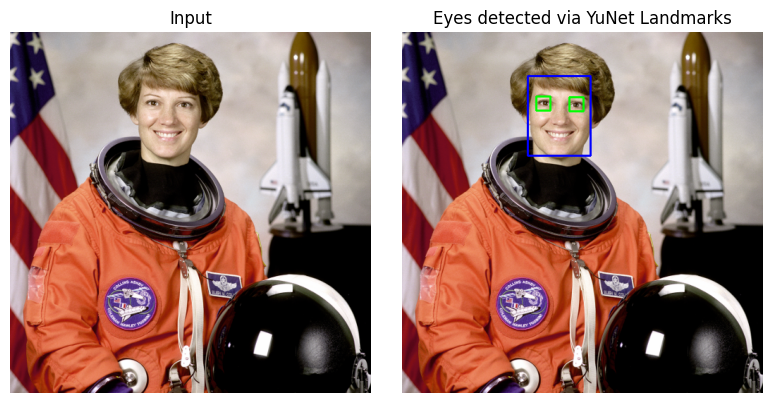

In [65]:
import os

img = load_image('astronaut')
h, w, _ = img.shape

# Ensure the modern YuNet ONNX model is available locally
model_path = "face_detection_yunet_2023mar.onnx"
if not os.path.exists(model_path):
    import urllib.request
    model_url = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
    urllib.request.urlretrieve(model_url, model_path)

# Initialize YuNet face detector
detector = cv2.FaceDetectorYN.create(
    model=model_path,
    config="",
    input_size=(w, h),
    score_threshold=0.9,
    nms_threshold=0.3,
    top_k=5000
)

_, faces = detector.detect(img)
out = img.copy()
total_eyes = 0

if faces is not None:
    for face in faces:
        # Draw Face bounding box
        box = list(map(int, face[:4]))
        fx, fy, fw, fh = box
        cv2.rectangle(out, (fx, fy), (fx + fw, fy + fh), (255, 0, 0), 2)

        # YuNet provides 5 landmarks: right eye, left eye, nose tip, mouth right corner, mouth left corner.
        # Landmarks start at index 4 (each landmark has x, y coords)
        # Index 4, 5 -> Right Eye (from camera perspective)
        # Index 6, 7 -> Left Eye (from camera perspective)
        landmarks = face[4:14].reshape(5, 2)
        right_eye = landmarks[0].astype(int)
        left_eye = landmarks[1].astype(int)

        # Draw a custom bounding box around each detected eye point
        eye_size = int(fw * 0.12)  # Dynamically scale the bounding box based on face width
        for eye in [right_eye, left_eye]:
            ex, ey = eye
            cv2.rectangle(out, (ex - eye_size, ey - eye_size), (ex + eye_size, ey + eye_size), (0, 255, 0), 2)
            total_eyes += 1

print("Eyes found:", total_eyes)
show([img, out], ["Input", "Eyes detected via YuNet Landmarks"], cols=2)

## Experiment 30 – Smile detection

Smiles found: 1


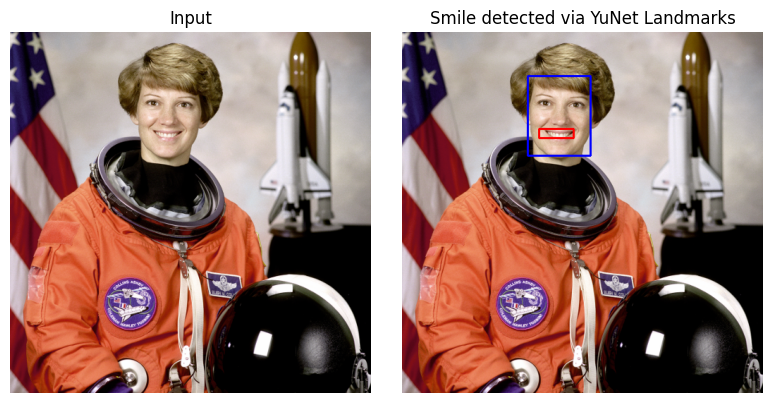

In [68]:
import os

img = load_image('astronaut')
h, w, _ = img.shape

# Ensure the modern YuNet ONNX model is available locally
model_path = "face_detection_yunet_2023mar.onnx"
if not os.path.exists(model_path):
    import urllib.request
    model_url = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
    urllib.request.urlretrieve(model_url, model_path)

# Initialize YuNet face detector
detector = cv2.FaceDetectorYN.create(
    model=model_path,
    config="",
    input_size=(w, h),
    score_threshold=0.9,
    nms_threshold=0.3,
    top_k=5000
)

_, faces = detector.detect(img)
out = img.copy()
total_smiles = 0

if faces is not None:
    for face in faces:
        # Draw Face bounding box (Blue)
        box = list(map(int, face[:4]))
        fx, fy, fw, fh = box
        cv2.rectangle(out, (fx, fy), (fx + fw, fy + fh), (255, 0, 0), 2)

        # YuNet provides 5 landmarks: right eye, left eye, nose tip, mouth right corner, mouth left corner.
        # Landmarks start at index 4 (each landmark has x, y coords)
        # Index 10, 11 -> Mouth Right Corner (from camera perspective)
        # Index 12, 13 -> Mouth Left Corner (from camera perspective)
        landmarks = face[4:14].reshape(5, 2)
        mouth_right = landmarks[3].astype(int)
        mouth_left = landmarks[4].astype(int)

        # Define smile/mouth bounding box using the mouth corner coordinates
        mx = min(mouth_right[0], mouth_left[0]) - int(fw * 0.05)
        my = min(mouth_right[1], mouth_left[1]) - int(fh * 0.05)
        mw = abs(mouth_right[0] - mouth_left[0]) + int(fw * 0.1)
        mh = int(fh * 0.12)

        cv2.rectangle(out, (mx, my), (mx + mw, my + mh), (0, 0, 255), 2)
        total_smiles += 1

print("Smiles found:", total_smiles)
show([img, out], ["Input", "Smile detected via YuNet Landmarks"], cols=2)

## Experiment 31 – Image segmentation using threshold values

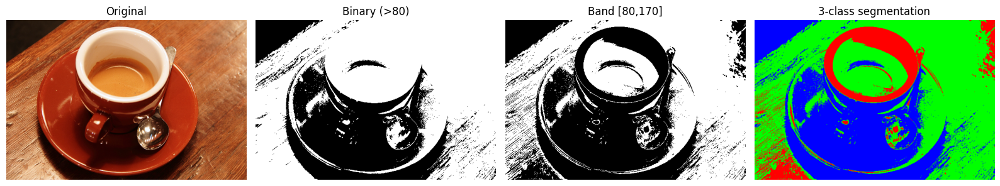

In [69]:
def segment(img, t_low=80, t_high=170):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, binary = cv2.threshold(gray, t_low, 255, cv2.THRESH_BINARY)
    band = cv2.inRange(gray, t_low, t_high)                              # pixels between the two thresholds
    seg = np.zeros_like(img)
    seg[gray < t_low] = (255, 0, 0); seg[(gray >= t_low) & (gray <= t_high)] = (0, 255, 0); seg[gray > t_high] = (0, 0, 255)
    return gray, binary, band, seg
img = load_image('coffee')
t1 = ask("Lower threshold", 80); t2 = ask("Upper threshold", 170)
gray, binary, band, seg = segment(img, t1, t2)
show([img, binary, band, seg], ["Original", f"Binary (>{t1})", f"Band [{t1},{t2}]", "3-class segmentation"], cols=4)

## Experiment 32 – White image with 4 coloured corner boxes (1/10 size)

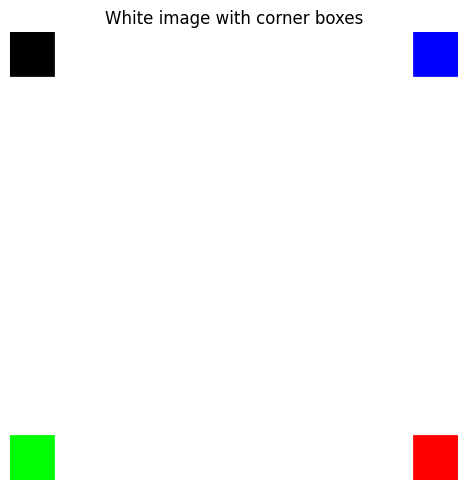

In [70]:
def corner_boxes(size):
    img = np.ones((size, size, 3), np.uint8) * 255                       # white image
    b = size // 10                                                       # box = 1/10th of the image
    img[0:b, 0:b]               = (0, 0, 0)       # top-left     : Black
    img[0:b, size-b:size]       = (255, 0, 0)     # top-right    : Blue  (BGR)
    img[size-b:size, 0:b]       = (0, 255, 0)     # bottom-left  : Green
    img[size-b:size, size-b:size] = (0, 0, 255)   # bottom-right : Red
    return img
size = ask("Enter image size (pixels)", 400)
show(corner_boxes(size), ["White image with corner boxes"], size=5)

## Experiment 33 – Draw a Rectangle on a white image

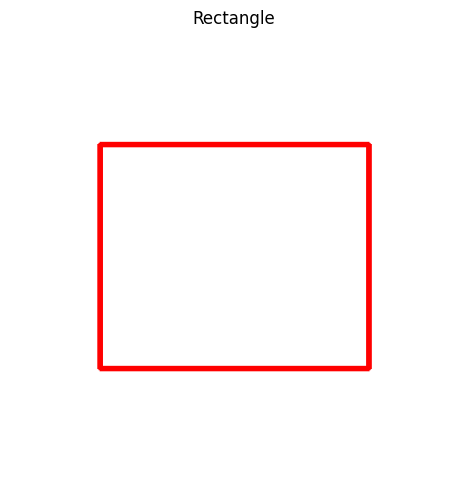

In [71]:
def draw_rectangle(size):
    img = np.ones((size, size, 3), np.uint8) * 255
    cv2.rectangle(img, (size//5, size//4), (size*4//5, size*3//4), (0, 0, 255), 4)
    return img
size = ask("Enter image size (pixels)", 400)
show(draw_rectangle(size), ["Rectangle"], size=5)

## Experiment 34 – Draw a Circle on a white image

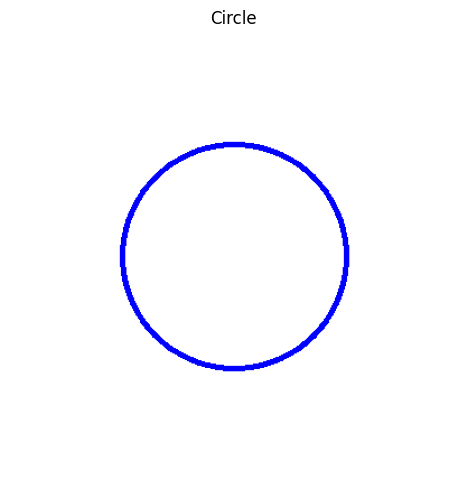

In [72]:
def draw_circle(size):
    img = np.ones((size, size, 3), np.uint8) * 255
    cv2.circle(img, (size//2, size//2), size//4, (255, 0, 0), 4)
    return img
size = ask("Enter image size (pixels)", 400)
show(draw_circle(size), ["Circle"], size=5)

## Experiment 35 – Put a user text string on an image

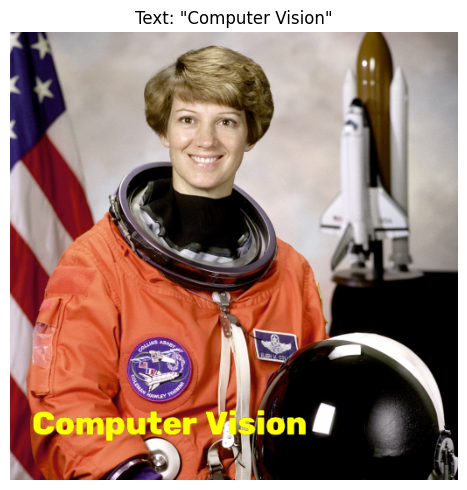

In [73]:
def put_text(img, text):
    out = img.copy(); h, w = out.shape[:2]
    scale = w / 400
    cv2.putText(out, text, (int(0.05*w), int(0.9*h)), cv2.FONT_HERSHEY_DUPLEX, scale, (0, 0, 0), 5, cv2.LINE_AA)
    cv2.putText(out, text, (int(0.05*w), int(0.9*h)), cv2.FONT_HERSHEY_DUPLEX, scale, (0, 255, 255), 2, cv2.LINE_AA)
    return out
text = ask("Enter the text", "Computer Vision", str)
show(put_text(load_image('astronaut'), text), [f'Text: "{text}"'], size=5)

## Experiment 36 – Background subtraction (colour-level based)

Colour level used (Otsu): 104.0


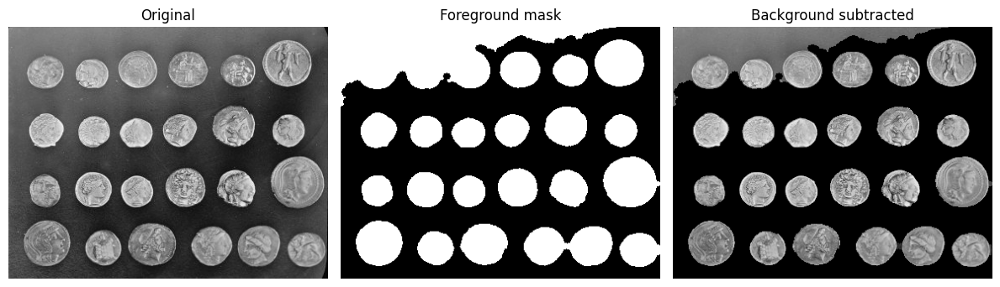

In [74]:
def subtract_background(img, level=None):
    gray = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    if level is None:   # automatic colour level (Otsu)
        level, mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    else:
        _, mask = cv2.threshold(gray, level, 255, cv2.THRESH_BINARY)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(mask)
    cv2.drawContours(filled, [c for c in cnts if cv2.contourArea(c) > 200], -1, 255, -1)   # fill holes
    fg_only = cv2.bitwise_and(img, img, mask=filled)                                        # background -> black
    return level, filled, fg_only

img = cv2.cvtColor(data.coins(), cv2.COLOR_GRAY2BGR)
level, mask, fg_only = subtract_background(img)
print("Colour level used (Otsu):", level)
show([img, mask, fg_only], ["Original", "Foreground mask", "Background subtracted"])

## Experiment 37 – Foreground subtraction (colour-level based)

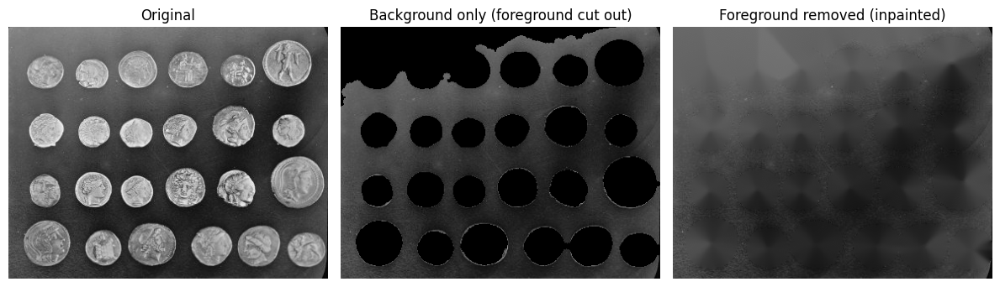

In [75]:
img = cv2.cvtColor(data.coins(), cv2.COLOR_GRAY2BGR)
level, mask, _ = subtract_background(img)
bg_only = cv2.bitwise_and(img, img, mask=cv2.bitwise_not(mask))                              # foreground cut out
removed = cv2.inpaint(img, cv2.dilate(mask, np.ones((7, 7), np.uint8)), 5, cv2.INPAINT_TELEA) # foreground erased & filled in
show([img, bg_only, removed], ["Original", "Background only (foreground cut out)", "Foreground removed (inpainted)"])

## Experiment 38 – Count the number of faces

Number of faces: 2


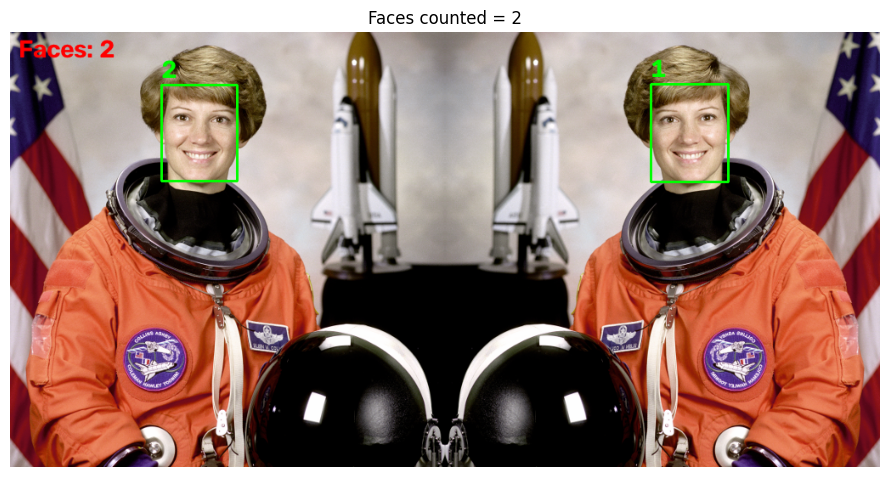

In [77]:
import os

def count_faces(img):
    h, w, _ = img.shape

    # Ensure the modern YuNet ONNX model is available locally
    model_path = "face_detection_yunet_2023mar.onnx"
    if not os.path.exists(model_path):
        import urllib.request
        model_url = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
        urllib.request.urlretrieve(model_url, model_path)

    # Initialize YuNet face detector with the current image dimensions
    detector = cv2.FaceDetectorYN.create(
        model=model_path,
        config="",
        input_size=(w, h),
        score_threshold=0.9,
        nms_threshold=0.3,
        top_k=5000
    )

    _, faces = detector.detect(img)
    out = img.copy()
    num_faces = len(faces) if faces is not None else 0

    if faces is not None:
        for i, face in enumerate(faces, 1):
            box = list(map(int, face[:4]))
            x, y, fw, fh = box
            cv2.rectangle(out, (x, y), (x + fw, y + fh), (0, 255, 0), 2)
            cv2.putText(out, str(i), (x, y - 8), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)

    cv2.putText(out, f"Faces: {num_faces}", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
    return num_faces, out

a = load_image('astronaut')
group = np.hstack([a, cv2.flip(a, 1)])                                   # a picture with two faces
n, out = count_faces(group)
print("Number of faces:", n)
show(out, [f"Faces counted = {n}"], size=9)

## Experiment 39 – Play a video in reverse mode in slow motion

In [78]:
def reverse_slow_motion(src, dst, slow_factor=3):
    frames, fps = read_frames(src)
    out = [f for f in frames[::-1] for _ in range(slow_factor)]          # reversed order + each frame repeated
    write_video(dst, out, fps); return len(frames), len(out)
make_moving_video('captured.avi')
a, b = reverse_slow_motion('captured.avi', 'reverse_slow.avi', 3)
print(f"{a} frames -> {b} frames (reverse, 3x slower)")
play('reverse_slow.avi')

90 frames -> 270 frames (reverse, 3x slower)


## Experiment 40 – Extract text from a video (OCR)

In [79]:
!apt-get -qq install -y tesseract-ocr > /dev/null
!pip -q install pytesseract

frame   0: 'COMPUTER VISION'
frame  10: 'COMPUTER VISION'
frame  20: 'SAI KUMAR'
frame  30: 'OPENCV LAB'
frame  40: 'OPENCV LAB'
frame  50: 'HELLO PYTHON'

Text extracted from video: ['COMPUTER VISION', 'SAI KUMAR', 'OPENCV LAB', 'HELLO PYTHON']


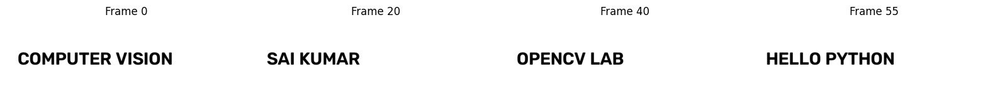

In [80]:
import pytesseract
# Generate a video whose scenes contain text
lines = ["COMPUTER VISION", "SAI KUMAR", "OPENCV LAB", "HELLO PYTHON"]
frames = []
for t in lines:
    for _ in range(15):
        f = np.full((200, 640, 3), 255, np.uint8)
        cv2.putText(f, t, (30, 120), cv2.FONT_HERSHEY_SIMPLEX, 1.6, (0, 0, 0), 4, cv2.LINE_AA)
        frames.append(f)
write_video('text_video.avi', frames, 15)

def extract_text_from_video(path, step=10):
    frs, _ = read_frames(path); found = []
    for i in range(0, len(frs), step):
        g = cv2.cvtColor(frs[i], cv2.COLOR_BGR2GRAY)
        _, th = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        txt = pytesseract.image_to_string(th, config='--psm 7').strip()
        if txt and txt not in found: found.append(txt)
        print(f"frame {i:3d}: {txt!r}")
    return found
result = extract_text_from_video('text_video.avi')
print("\nText extracted from video:", result)
show([frames[0], frames[20], frames[40], frames[55]], ["Frame 0", "Frame 20", "Frame 40", "Frame 55"], cols=4, size=4)

---
**End of record – SAI KUMAR PABBISETTY (192411240) – ITA0515 Computer Vision**